<a href="https://colab.research.google.com/github/davichomendez1901-byte/Simulaci-n-Remix/blob/main/Proceso_derivados_MB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Proceso derivados del MB(**Movimiento Brawniano**)
$$ X_t = B_T - tB $$
$$ 0 <= t <= 1 $$

In [ ]:
#Partimos del codigo de movimiento Brawniano que anteriormente
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
def browniano(T,n):
  dt = T / n
  B = np.zeros(n+1)
  for i in range(n):
    Z = np.random.normal(0,1)
    B[i+1] = B[i] + np.sqrt(dt) * Z
  return B


In [ ]:
#Ahora construimos el puente Brawniano:
def Puente_Brawniano(n):
    #vector de tiempos:
  t = np.linspace(0,1,n+1)
  #Simulamos Moviimientos Brawniano:
  B = browniano(1,n)
  #Construimos el puente Brawniano:
  X = B - t * B[-1]
  return X, t

In [ ]:
n = 1000
X, t = Puente_Brawniano(n)

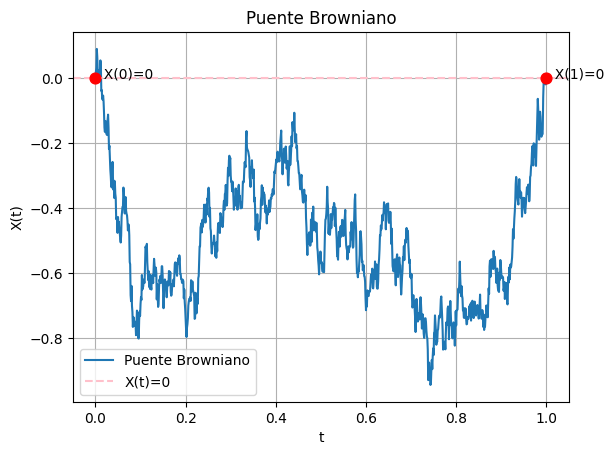

In [ ]:
plt.plot(t, X, label="Puente Browniano")

# Línea horizontal en cero
plt.axhline(0, linestyle="--", color = "pink", label="X(t)=0")

# Marcar los extremos
plt.scatter([0, 1], [0, 0], s=60, zorder=5, color = 'red')

# Etiquetas
plt.text(0, 0, "  X(0)=0")
plt.text(1, 0, "  X(1)=0")

plt.xlabel("t")
plt.ylabel("X(t)")
plt.title("Puente Browniano")

plt.grid()
plt.legend()
plt.show()

In [ ]:
from IPython.core.debugger import linecache
def Brawn_deriv(T, n, mu, sigma):
  dt = T /n
  t = np.linspace(0,T, n+1)
  X = np.zeros(n+1)
  for i in range(n):
    Z = np.random.normal(0,1)
    X[i+1] = X[i] + mu*dt + sigma*np.sqrt(dt) * Z
  return  t, X

In [ ]:
T = 1
n = 1000
mu = 2
sigma = 0.5
t, X = Brawn_deriv(T, n, mu, sigma)


<function matplotlib.pyplot.show(close=None, block=None)>

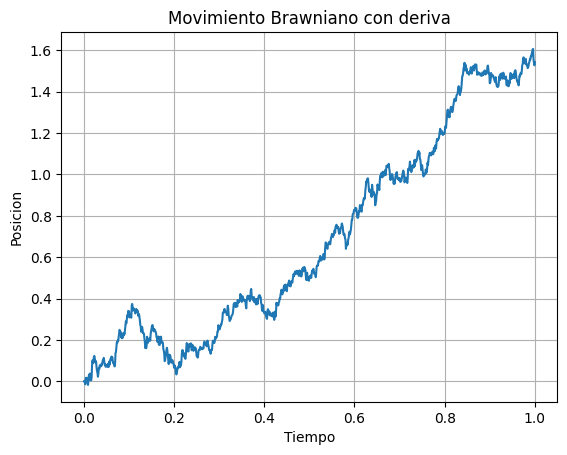

In [ ]:
plt.plot(t,X)
plt.xlabel('Tiempo')
plt.ylabel('Posicion')
plt.title('Movimiento Brawniano con deriva')
plt.grid()
plt.show
#

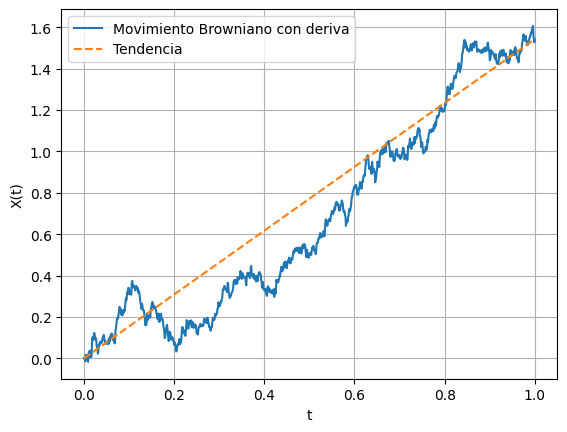

In [ ]:
# Pendiente estimada usando inicio y final
pendiente = (X[-1] - X[0]) / (t[-1] - t[0])

# Recta con esa pendiente
recta = X[0] + pendiente * t

plt.plot(t, X, label="Movimiento Browniano con deriva")
plt.plot(t, recta, "--", label="Tendencia")

plt.xlabel("t")
plt.ylabel("X(t)")
plt.legend()
plt.grid()
plt.show()